# 08. Phân tích cơ chế của giá trị neo

Sổ tay notebook 04 cho thứ tự B tốt hơn D tốt hơn C tốt hơn A. Thứ tự này trả lời câu hỏi neo nào tốt nhất, nhưng chưa trả lời câu hỏi tại sao. Sổ tay này tách hiệu ứng thành các thành phần đo được, bằng bốn cấu hình đối chứng mới.

- Neo `Z` trả về không, tức là không neo. Đây là mốc dưới. Nó cho biết bản thân cơ chế trừ rồi cộng trả lại đóng góp bao nhiêu, tách khỏi việc chọn đúng giá trị.
- Neo `O` lấy quan sát thật xa nhất trong cửa sổ thay vì gần nhất. Đây là phép thử xáo trộn. Nếu `O` tệ gần bằng `A` thì tính gần nhất mới là yếu tố quyết định. Nếu `O` vẫn tốt gần bằng `B` thì điều quan trọng chỉ là neo phải là một giá trị thật, không phải giá trị đã điền.
- Neo `E` và `F` giống `C` và `D` về công thức, chỉ khác điểm khởi tạo của tham số suy giảm. Ở `C` và `D`, tham số khởi tạo tại không nên hệ số suy giảm ban đầu bằng khoảng 0,693, tức cổng bắt đầu ở trạng thái co rất mạnh về gần giá trị trung bình. Ở `E` và `F`, tham số khởi tạo tại âm sáu nên hệ số suy giảm ban đầu gần bằng không, tức cổng bắt đầu đúng tại neo `B` rồi học rời khỏi đó nếu có lợi.

Điểm phương pháp cần làm rõ: kết luận ở notebook 04 rằng cổng suy giảm học được thua neo tĩnh đang bị lẫn giữa hai nguyên nhân: dung lượng của cổng và điểm khởi tạo của nó. Cấu hình `E` và `F` tách hai nguyên nhân này ra.

Bốn cấu hình A, B, C, D không chạy lại ở đây. Sổ tay đọc chúng từ thư mục `bo_sung_04_neo_abcd` để tránh trùng lặp tính toán.

> **Vị trí trong chuỗi tái lập:** notebook 08 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo.
>
> **Thư mục kết quả:** `Output/processed/bo_sung_11_co_che_neo/`.
>
> **Mã định danh nội bộ:** `W2_11`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "bo_sung_11_co_che_neo"  #@param {type:"string"}
DANH_SACH_NEO = "Z,O,E,F"  #@param {type:"string"}
NGUON_ABCD = "bo_sung_04_neo_abcd"  #@param {type:"string"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

NEO = [t.strip() for t in DANH_SACH_NEO.split(",") if t.strip()]
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_11_co_che_neo
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:19:35
run_tag      bo_sung_11_co_che_neo
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, chỉ số và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


## 3. Chạy bốn cấu hình đối chứng

Cùng dữ liệu, cùng ngân sách huấn luyện, cùng số hạt giống như notebook 04, nên tám giá trị neo đặt cạnh nhau được trong cùng một bảng.

In [8]:
ket_qua = {}
t0 = time.time()
for neo in NEO:
    for seed in range(N_SEEDS):
        p = chay_mot_cau_hinh("nlinear", anchor=neo, seed=seed,
                              nhan="nlinear_neo" + neo + "_s" + str(seed))
        ket_qua.setdefault(neo, []).append(p)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


nlinear_neoZ_s0                  MSE_obs 0.4876 | MAE_obs 0.4727 | 10 giây | 876 tham số
nlinear_neoZ_s1                  MSE_obs 0.4868 | MAE_obs 0.4707 | 7 giây | 876 tham số
nlinear_neoZ_s2                  MSE_obs 0.4873 | MAE_obs 0.4712 | 6 giây | 876 tham số
nlinear_neoO_s0                  MSE_obs 0.4859 | MAE_obs 0.4698 | 11 giây | 876 tham số
nlinear_neoO_s1                  MSE_obs 0.486 | MAE_obs 0.4704 | 10 giây | 876 tham số
nlinear_neoO_s2                  MSE_obs 0.486 | MAE_obs 0.4704 | 10 giây | 876 tham số
nlinear_neoE_s0                  MSE_obs 0.4358 | MAE_obs 0.4368 | 7 giây | 877 tham số
nlinear_neoE_s1                  MSE_obs 0.4362 | MAE_obs 0.4372 | 8 giây | 877 tham số
nlinear_neoE_s2                  MSE_obs 0.4364 | MAE_obs 0.4378 | 7 giây | 877 tham số
nlinear_neoF_s0                  MSE_obs 0.4353 | MAE_obs 0.4365 | 7 giây | 913 tham số
nlinear_neoF_s1                  MSE_obs 0.4357 | MAE_obs 0.4368 | 8 giây | 913 tham số
nlinear_neoF_s2               

In [9]:
tong_hop = {}
for neo, ds in ket_qua.items():
    mse = np.array([d["test"]["mse"] for d in ds])
    mae = np.array([d["test"]["mae"] for d in ds])
    tong_hop[neo] = {
        "mse_trung_binh": float(mse.mean()),
        "mse_do_lech_chuan": float(mse.std(ddof=1)) if len(mse) > 1 else 0.0,
        "mae_trung_binh": float(mae.mean()),
        "so_tham_so": ds[0]["n_params"],
        "giay_trung_binh": float(np.mean([d["train_time_sec"] for d in ds])),
        "cac_gia_tri_mse": [float(v) for v in mse],
        "nguon": "so tay nay",
    }
    print("Neo", neo, "| MSE", round(float(mse.mean()), 6),
          "+/-", round(float(mse.std(ddof=1)) if len(mse) > 1 else 0.0, 6),
          "| MAE", round(float(mae.mean()), 6), "|", ds[0]["n_params"], "tham số")


Neo Z | MSE 0.487259 +/- 0.000392 | MAE 0.471517 | 876 tham số
Neo O | MSE 0.485963 +/- 6.6e-05 | MAE 0.47022 | 876 tham số
Neo E | MSE 0.436131 +/- 0.000304 | MAE 0.437298 | 877 tham số
Neo F | MSE 0.435637 +/- 0.000281 | MAE 0.436924 | 913 tham số


In [10]:
# Đọc lại bốn neo cũ từ notebook 04 để có bảng tám neo đầy đủ.
f04 = OUT / "processed" / NGUON_ABCD / "W2_so_sanh_bon_phuong_an_neo.json"
if f04.exists():
    d04 = json.loads(f04.read_text())
    for neo, v in d04.get("tong_hop", {}).items():
        if neo in tong_hop:
            continue
        v = dict(v)
        v["nguon"] = NGUON_ABCD
        tong_hop[neo] = v
    print("Đã đọc thêm", len(d04.get("tong_hop", {})), "cấu hình từ", f04.name)
else:
    print("Chưa thấy kết quả của notebook 04, bảng sẽ chỉ có bốn neo mới")

thu_tu = sorted(tong_hop, key=lambda k: tong_hop[k]["mse_trung_binh"])
print("Thứ tự từ tốt tới kém theo MSE:", " < ".join(thu_tu))


Đã đọc thêm 4 cấu hình từ W2_so_sanh_bon_phuong_an_neo.json
Thứ tự từ tốt tới kém theo MSE: F < B < E < D < C < O < Z < A


## 4. Phân rã hiệu ứng thành ba thành phần

Ba hiệu số dưới đây được tính từ bảng tám neo, mỗi hiệu số cô lập đúng một yếu tố. Cách đọc này chỉ hợp lệ vì tất cả các cấu hình dùng cùng dữ liệu và cùng ngân sách.

In [11]:
def lay(k):
    return tong_hop[k]["mse_trung_binh"] if k in tong_hop else None


def hieu(a, b):
    va, vb = lay(a), lay(b)
    return None if va is None or vb is None else float(va - vb)


phan_ra = {
    "co_che_tru_va_cong_lai": hieu("A", "Z"),
    "chon_gia_tri_that_thay_vi_gia_tri_dien": hieu("B", "A"),
    "tinh_gan_nhat_so_voi_xa_nhat": hieu("B", "O"),
    "cong_suy_giam_khoi_tao_co_manh": hieu("C", "B"),
    "cong_suy_giam_khoi_tao_tai_neo_B": hieu("E", "B"),
    "cong_rieng_tung_kenh_khoi_tao_tai_neo_B": hieu("F", "B"),
}
for k, v in phan_ra.items():
    print(k.ljust(42), "không đủ dữ liệu" if v is None else round(v, 6))


co_che_tru_va_cong_lai                     0.000773
chon_gia_tri_that_thay_vi_gia_tri_dien     -0.051995
tinh_gan_nhat_so_voi_xa_nhat               -0.049927
cong_suy_giam_khoi_tao_co_manh             0.014722
cong_suy_giam_khoi_tao_tai_neo_B           9.5e-05
cong_rieng_tung_kenh_khoi_tao_tai_neo_B    -0.000399


In [12]:
def nap_tong_trung_binh(tien_to, thu_muc=None):
    thu_muc = RUNS if thu_muc is None else thu_muc
    ses, aes, dem = [], [], None
    for seed in range(N_SEEDS):
        d = np.load(thu_muc / (tien_to + "_s" + str(seed) + "_patient_sums.npz"))
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


NGUON_RUNS = OUT / "processed" / NGUON_ABCD / "runs"
bat_cap = {}
if (NGUON_RUNS / "nlinear_neoB_s0_patient_sums.npz").exists():
    se_b, ae_b, dem = nap_tong_trung_binh("nlinear_neoB", NGUON_RUNS)
    for neo in NEO:
        se_x, ae_x, _ = nap_tong_trung_binh("nlinear_neo" + neo)
        if len(se_x) != len(se_b):
            print("Bỏ qua neo", neo, "vì số hồ sơ không khớp")
            continue
        r = hieu_so_bat_cap(se_x, ae_x, se_b, ae_b, dem, seed=0)
        bat_cap["neo" + neo + "_tru_neoB"] = {
            k: v for k, v in r.items() if not k.startswith("mau_bootstrap")}
        print("Neo", neo, "trừ neo B | hiệu MSE", round(r["hieu_mse"], 6),
              "| khoảng tin cậy", [round(v, 6) for v in r["hieu_mse_ci"]],
              "| p", round(r["p_hai_phia_mse"], 4))
else:
    print("Không thấy tệp tổng theo hồ sơ của neo B, bỏ phần bắt cặp")


Neo Z trừ neo B | hiệu MSE 0.051222 | khoảng tin cậy [0.044005, 0.05839] | p 0.0
Neo O trừ neo B | hiệu MSE 0.049927 | khoảng tin cậy [0.043098, 0.056611] | p 0.0
Neo E trừ neo B | hiệu MSE 9.5e-05 | khoảng tin cậy [-3e-06, 0.000184] | p 0.06
Neo F trừ neo B | hiệu MSE -0.000399 | khoảng tin cậy [-0.000629, -0.00021] | p 0.0


## 5. Hệ số suy giảm đã học được

In [13]:
# Học lại một lần neo E để đọc giá trị tham số suy giảm sau huấn luyện.
cong_da_hoc = {}
for neo in [n for n in ("E", "F") if n in NEO]:
    dat_hat_giong(0)
    m = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind="nlinear", anchor=neo).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), lr=LR)
    tai = DataLoader(SPLITS["train"], batch_size=BATCH, shuffle=True)
    for ep in range(10):
        m.train()
        for x, mxx, y, myy in tai:
            x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
            opt.zero_grad()
            tinh_mat_mat(m(x, mxx), y, myy, "mse").backward()
            opt.step()
    rate = F.softplus(m.w_decay).detach().cpu().numpy()
    nua_doi = float(np.median(np.log(2.0) / np.maximum(rate, 1e-8)))
    cong_da_hoc[neo] = {"he_so_suy_giam_trung_vi": float(np.median(rate)),
                        "ban_chu_ky_gio": nua_doi}
    print("Neo", neo, "| hệ số suy giảm trung vị", round(float(np.median(rate)), 5),
          "| bán chứ kỳ", round(nua_doi, 2), "giờ")


Neo E | hệ số suy giảm trung vị 0.00222 | bán chứ kỳ 312.15 giờ
Neo F | hệ số suy giảm trung vị 0.00248 | bán chứ kỳ 279.98 giờ


## 6. Hình và tệp kết quả

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_11_co_che_neo/figures/fig25_tam_dinh_nghia_neo.png
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_11_co_che_neo/figures/fig26_phan_ra_hieu_ung_neo.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_11_co_che_neo/figures/fig26_phan_ra_hieu_ung_neo.png')

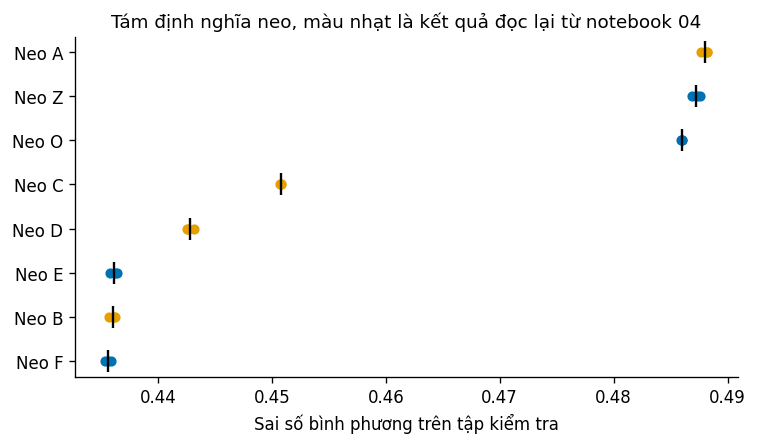

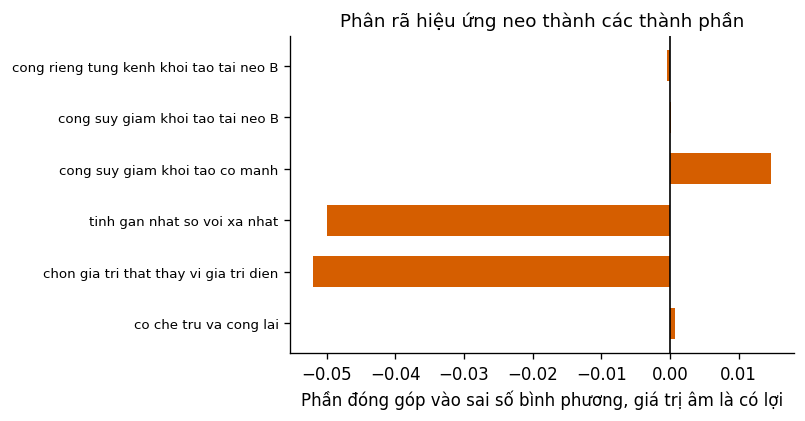

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for i, neo in enumerate(thu_tu):
    v = np.array(tong_hop[neo]["cac_gia_tri_mse"])
    mau = PALETTE[0] if tong_hop[neo]["nguon"] == "so tay nay" else PALETTE[4]
    ax.scatter(v, np.full_like(v, i, dtype=float), s=26, color=mau, zorder=3)
    ax.scatter([v.mean()], [i], marker="|", s=170, color="black", zorder=4)
ax.set_yticks(range(len(thu_tu)))
ax.set_yticklabels(["Neo " + n for n in thu_tu])
ax.set_xlabel("Sai số bình phương trên tập kiểm tra")
ax.set_title("Tám định nghĩa neo, màu nhạt là kết quả đọc lại từ notebook 04")
luu_hinh(fig, "fig25_tam_dinh_nghia_neo.png")

co = [(k, v) for k, v in phan_ra.items() if v is not None]
fig, ax = plt.subplots(figsize=(6.6, 3.4))
ax.barh(np.arange(len(co)), [v for _, v in co], color=PALETTE[1], height=0.6)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_yticks(np.arange(len(co)))
ax.set_yticklabels([k.replace("_", " ") for k, _ in co], fontsize=8)
ax.set_xlabel("Phần đóng góp vào sai số bình phương, giá trị âm là có lợi")
ax.set_title("Phân rã hiệu ứng neo thành các thành phần")
luu_hinh(fig, "fig26_phan_ra_hieu_ung_neo.png")


In [15]:
bao_cao = {"kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
           "read_tag": READ_TAG, "run_tag": RUN_TAG,
           "giao_thuc": meta["protocol"], "n_seeds": N_SEEDS,
           "neo_moi": NEO, "tong_hop": tong_hop,
           "thu_tu_tot_den_kem": thu_tu, "phan_ra_hieu_ung": phan_ra,
           "bat_cap_theo_benh_nhan": bat_cap,
           "cong_suy_giam_da_hoc": cong_da_hoc, "env": ENV}
(RUN_DIR / "W2_co_che_neo.json").write_text(
    json.dumps(bao_cao, ensure_ascii=False, indent=2))
print("Đã ghi", RUN_DIR / "W2_co_che_neo.json")


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_11_co_che_neo/W2_co_che_neo.json


## 7. Cách đọc kết quả

- Nếu `E` hoặc `F` tốt hơn `B` thì cổng suy giảm thực sự có giá trị, và kết luận cũ ở notebook 04 phải được sửa thành một phát biểu về điểm khởi tạo chứ không phải về bản thân cổng.
- Nếu `E` và `F` vẫn không tốt hơn `B` thì kết luận cũ được củng cố, và còn mạnh hơn trước vì đã loại được giải thích bằng điểm khởi tạo.
- `tinh_gan_nhat_so_voi_xa_nhat` là con số cần cho phần thảo luận cơ chế. Nó tách giữa hai cách diễn giải: neo tốt vì nó gần về thời gian, hay neo tốt chỉ vì nó là một số đo thật.
- `ban_chu_ky_gio` đọc được theo nghĩa lâm sàng. Nó cho biết mô hình tự học được rằng một phép đo mất một nửa giá trị tham chiếu sau bao nhiêu giờ.